# **Homework 04 - Machine Learning - Zoomcamp 2026**

## **Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## **Download lead scoring dataset**

In [2]:
DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df_leads = pd.read_csv(DATA_URL)

df_leads.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


The target for this classification task is the `converted` column: whether the client signed up to the platform (`1`) or not (`0`).

## **Preparing the dataset**

Check if there are missing values in the features:

In [3]:
df_leads.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

As in Homework 03, we separate the columns by type. The `str` columns are the categorical features, while the `int64` and `float64` ones are the numerical features (except the target `converted`):

In [4]:
target = "converted"

# Get a list with all categorical features
categorical = list(df_leads.select_dtypes(exclude="number").columns)

# Get a list with all numerical features (without the target)
numerical = list(df_leads.select_dtypes(include="number").columns.drop(target))

print(f"Categorical features: {categorical}")
print(f"Numerical features: {numerical}")

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


Now we replace the missing values with `'NA'` for the categorical features and with `0.0` for the numerical ones:

In [5]:
df_leads[categorical] = df_leads[categorical].fillna("NA")
df_leads[numerical] = df_leads[numerical].fillna(0.0)

df_leads.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## **Split the dataset**

We split the dataset into 60% train, 20% validation and 20% test. Note that this homework uses `random_state=1`, while Homework 03 used `random_state=42`:

In [6]:
# Split the dataset into 80% (train + val) and 20% test
df_full_train, df_test = train_test_split(df_leads, test_size=0.2, random_state=1)

# Split the full train into 60% train and 20% validation (20% / 80% = 25%)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [7]:
# Reset indexes to get sequential ascending order
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [8]:
# Store the target variable of each dataset division, before deleting it
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

In [9]:
# Delete the target column from train, validation and test datasets
del df_train[target]
del df_val[target]
del df_test[target]

We keep the target inside `df_full_train`, since it will be split again into folds in Questions 05 and 06.

## **Question 01**

- **Problem statement: Using each numerical variable as a score, which one has the highest ROC AUC with the target on the training set: `lead_score`, `number_of_courses_viewed`, `interaction_count` or `annual_income`?**

### **Solution**

The ROC AUC measures how well a score separates the positive from the negative examples: it is the probability that a randomly chosen positive example gets a higher score than a randomly chosen negative one. Since it only depends on the ordering of the values, we can use any numerical variable directly as a "prediction".

If the AUC is below 0.5, the variable is negatively correlated with the target, so we invert it by putting a `-` in front of it.

In [10]:
auc_scores = {}

for variable in numerical:
    auc = roc_auc_score(y_train, df_train[variable])

    # Invert the variable if it is negatively correlated with the target
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[variable])

    auc_scores[variable] = auc

pd.Series(auc_scores).sort_values(ascending=False).to_frame(name="AUC")

,AUC
lead_score,0.788225
interaction_count,0.764920
number_of_courses_viewed,0.722989
annual_income,0.608198


All the AUCs are already above 0.5, so none of the variables needed to be inverted.

> **Answer: `lead_score` has the highest AUC (0.788).**

## **Question 02**

- **Problem statement: What's the AUC of the logistic regression on the validation dataset (rounded to 3 digits)?**

### **Solution**

Since we will train the same model several times in this homework, we wrap the one-hot encoding and the training in a `train` function, and the prediction in a `predict` function:

In [11]:
features = categorical + numerical


def train(df: pd.DataFrame, y: np.ndarray, C: float = 1.0) -> tuple[DictVectorizer, LogisticRegression]:
    """One-hot encode the features and train a logistic regression.

    Args:
        df: DataFrame with the training features.
        y: Target values of the training set.
        C: Inverse of the regularization strength.

    Returns:
        The fitted DictVectorizer and the trained model.
    """
    dicts = df[features].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df: pd.DataFrame, dv: DictVectorizer, model: LogisticRegression) -> np.ndarray:
    """Return the predicted probability of conversion for each row."""
    dicts = df[features].to_dict(orient="records")
    X = dv.transform(dicts)

    return model.predict_proba(X)[:, 1]

In [12]:
dv, model = train(df_train, y_train, C=1.0)

y_pred = predict(df_val, dv, model)

auc = roc_auc_score(y_val, y_pred)
auc

0.7318222288173319

For visualization purposes, we plot the ROC curve of the model, which shows the true positive rate (TPR) against the false positive rate (FPR) for every threshold. The dashed line represents a random model (AUC = 0.5):

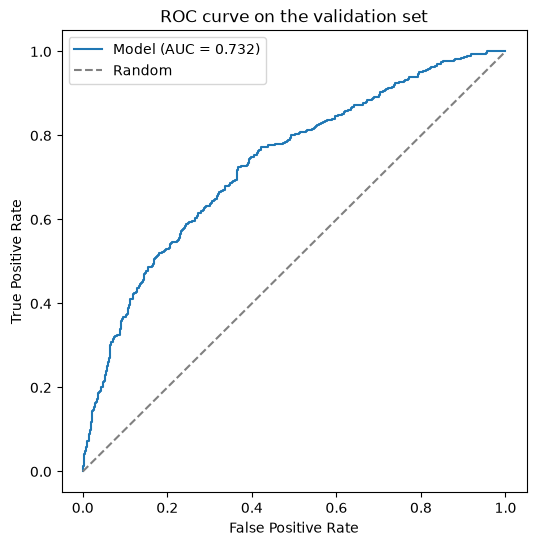

In [13]:
fpr, tpr, _ = roc_curve(y_val, y_pred)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve on the validation set")
plt.legend()
plt.show()

> **Answer: The AUC on the validation dataset is 0.732.**

## **Question 03**

- **Problem statement: At which threshold do the precision and recall curves intersect?**

### **Solution**

For each threshold `t`, a lead is predicted as converted when its probability is `>= t`. Comparing the predictions with the actual values gives the four cells of the confusion matrix, from which we compute:

- **Precision** $= \frac{TP}{TP + FP}$: the fraction of predicted conversions that actually converted.
- **Recall** $= \frac{TP}{TP + FN}$: the fraction of actual conversions that the model found.

At high thresholds the model may predict no positive at all ($TP + FP = 0$). In that case we set the precision to 0, as Scikit-Learn does with `zero_division=0`.

In [14]:
thresholds = np.linspace(0, 1, 101)

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

scores = []
for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    scores.append((t, tp, fp, fn, tn))

df_scores = pd.DataFrame(scores, columns=["threshold", "tp", "fp", "fn", "tn"])

predicted_positives = df_scores["tp"] + df_scores["fp"]
df_scores["precision"] = np.where(predicted_positives > 0, df_scores["tp"] / predicted_positives.replace(0, 1), 0.0)
df_scores["recall"] = df_scores["tp"] / (df_scores["tp"] + df_scores["fn"])

df_scores[::10]

,threshold,tp,fp,fn,tn,precision,recall
0,0.0,586,414,0,0,0.586000,1.000000
10,0.1,586,414,0,0,0.586000,1.000000
20,0.2,586,414,0,0,0.586000,1.000000
30,0.3,586,403,0,11,0.592518,1.000000
40,0.4,573,362,13,52,0.612834,0.977816
50,0.5,531,294,55,120,0.643636,0.906143
60,0.6,457,190,129,224,0.706337,0.779863
70,0.7,311,82,275,332,0.791349,0.530717
80,0.8,139,23,447,391,0.858025,0.237201
90,0.9,19,1,567,413,0.950000,0.032423


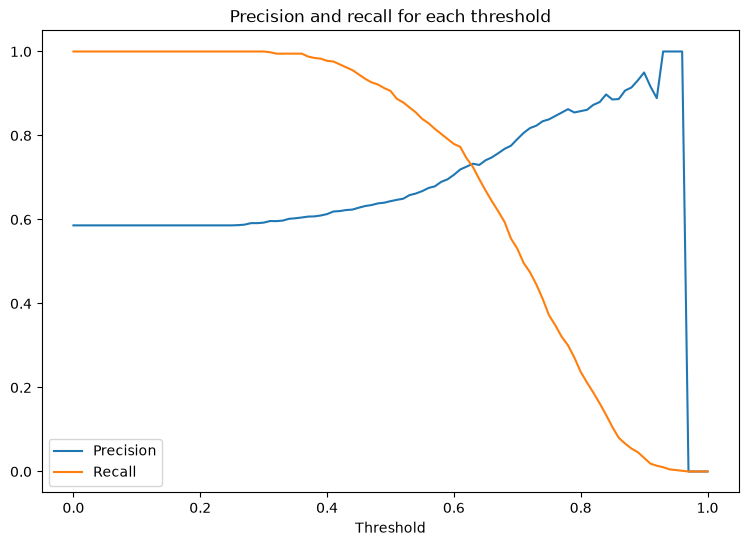

In [15]:
plt.figure(figsize=(9, 6))
plt.plot(df_scores["threshold"], df_scores["precision"], label="Precision")
plt.plot(df_scores["threshold"], df_scores["recall"], label="Recall")
plt.xlabel("Threshold")
plt.title("Precision and recall for each threshold")
plt.legend()
plt.show()

To find the intersection, we ignore the thresholds at which both metrics are zero and take the threshold with the smallest absolute difference between precision and recall:

In [16]:
df_valid = df_scores[(df_scores["precision"] > 0) | (df_scores["recall"] > 0)].copy()
df_valid["difference"] = (df_valid["precision"] - df_valid["recall"]).abs()

df_valid.sort_values(by="difference").head()[["threshold", "precision", "recall", "difference"]]

,threshold,precision,recall,difference
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


> **Answer: The precision and recall curves intersect at the threshold 0.63.**

## **Question 04**

- **Problem statement: At which threshold is the F1 score maximal?**

### **Solution**

The F1 score is the harmonic mean of precision and recall:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

When both precision and recall are zero, the F1 is also set to zero.

In [17]:
precision_plus_recall = df_scores["precision"] + df_scores["recall"]
df_scores["f1"] = np.where(
    precision_plus_recall > 0,
    2 * df_scores["precision"] * df_scores["recall"] / precision_plus_recall.replace(0, 1),
    0.0,
)

df_scores.sort_values(by="f1", ascending=False).head()[["threshold", "precision", "recall", "f1"]]

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


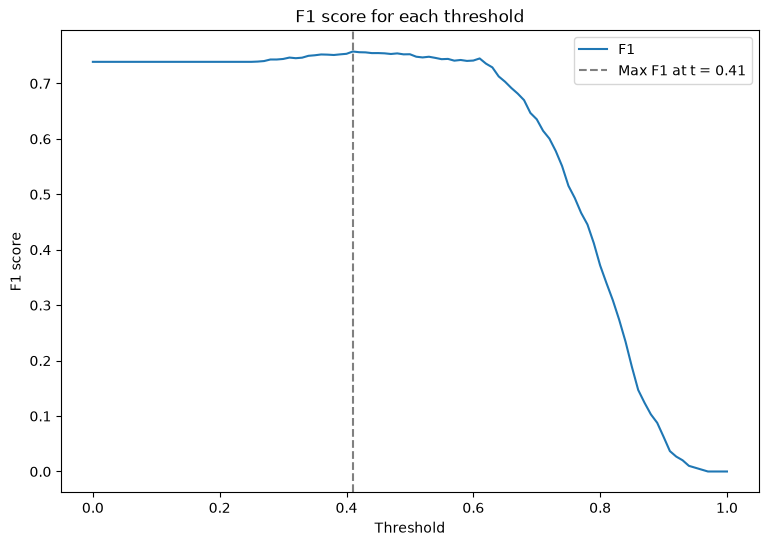

In [18]:
best = df_scores.loc[df_scores["f1"].idxmax()]

plt.figure(figsize=(9, 6))
plt.plot(df_scores["threshold"], df_scores["f1"], label="F1")
plt.axvline(best["threshold"], linestyle="--", color="gray", label=f"Max F1 at t = {best['threshold']:.2f}")
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("F1 score for each threshold")
plt.legend()
plt.show()

> **Answer: The F1 score is maximal at the threshold 0.41.**

## **Question 05**

- **Problem statement: Using 5-Fold cross-validation on the full training set, how large is the standard deviation of the AUC scores across the folds?**

### **Solution**

In K-Fold cross-validation, `df_full_train` is split into 5 parts (folds). Each fold is used once as the validation set, while the other 4 are used for training. This gives 5 AUC scores, and their standard deviation tells us how much the model performance depends on the particular split of the data.

In [19]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    y_fold_train = df_fold_train[target].values
    y_fold_val = df_fold_val[target].values

    dv, model = train(df_fold_train, y_fold_train, C=1.0)
    y_fold_pred = predict(df_fold_val, dv, model)

    scores.append(roc_auc_score(y_fold_val, y_fold_pred))

print(f"AUC per fold: {np.round(scores, 3)}")
print(f"mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}")

AUC per fold: [0.731 0.73  0.736 0.741 0.721]
mean = 0.732, std = 0.007


Since `train` and `predict` only use the columns in `features`, we don't need to delete the target from the folds.

> **Answer: The standard deviation of the scores across the folds is 0.007.**

## **Question 06**

- **Problem statement: Using 5-Fold cross-validation, which `C` among `[0.000001, 0.001, 1]` leads to the best mean ROC AUC?**

### **Solution**

We repeat the cross-validation of Question 05 for each value of `C`, using the same `KFold` parameters, and compute the mean and the standard deviation of the AUC scores (rounded to 3 digits):

In [20]:
results = []
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train[target].values
        y_fold_val = df_fold_val[target].values

        dv, model = train(df_fold_train, y_fold_train, C=C)
        y_fold_pred = predict(df_fold_val, dv, model)

        scores.append(roc_auc_score(y_fold_val, y_fold_pred))

    results.append((C, round(np.mean(scores), 3), round(np.std(scores), 3)))

df_tuning = pd.DataFrame(results, columns=["C", "mean_auc", "std_auc"])
df_tuning

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


Sorting by the highest mean AUC, then by the lowest std and then by the smallest `C` (the tie-breaking rules of the homework):

In [21]:
df_tuning.sort_values(by=["mean_auc", "std_auc", "C"], ascending=[False, True, True])

,C,mean_auc,std_auc
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
0,0.000001,0.617,0.019


> **Answer: `C = 0.001` leads to the best mean ROC AUC (0.749 ± 0.010).**

Note that `C = 0.001` performs better than `C = 1`. The stronger regularization reduces the weight of `annual_income`, which is on a much larger scale than the other features and was hurting the model already in Homework 03. With `C = 0.000001` the regularization is too strong and the model underfits.